# Ecommerce AI: entrenamiento y experimentación (Entrega 3)

Fundamentos de Inteligencia Artificial · LITIID73

Este notebook ejecuta **el mismo código del repositorio** (`src/`): no tiene lógica propia. Corre el entrenamiento completo, muestra la matriz de experimentos, las gráficas y una llamada real a `predecir()`.

- En **Colab**: *Entorno de ejecución → Ejecutar todo*. Clona el repositorio solo.
- En **local**: abrirlo desde `notebooks/` con el repositorio ya clonado.

In [1]:
import os, subprocess, sys

# Ubica la raíz del repositorio; si no está (Colab), lo clona.
if not os.path.exists('src'):
    if os.path.exists('../src'):
        os.chdir('..')
    else:
        subprocess.run(['git', 'clone', 'https://github.com/AlexRecaman/ecommerce-ai'], check=True)
        os.chdir('ecommerce-ai')
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
print('Directorio de trabajo:', os.getcwd())

Directorio de trabajo: C:\Users\recam\ecommerce-ai


## 1. Entrenamiento

Comando de reproducibilidad (una línea):

```
python -m src.models.train --data data/raw/E-commerce_Customer_Segmentation_2026.csv --output models/
```

In [2]:
r = subprocess.run([sys.executable, '-m', 'src.models.train', '--data', 'data/raw/E-commerce_Customer_Segmentation_2026.csv',
                    '--output', 'models/'], capture_output=True, text=True, encoding='utf-8')
print(r.stdout)
print(r.stderr)
assert r.returncode == 0, 'el entrenamiento falló'


[INFO] Cargando dataset: data/raw/E-commerce_Customer_Segmentation_2026.csv (50,000 registros, 53 columnas)
[INFO] Limpieza: 0 duplicados, nulos imputados {'preferred_category_2': 16743, 'preferred_category_3': 33257, 'social_media_presence': 12420, 'loyalty_tier': 1272}, nulos restantes 0
[INFO] Se excluyen 24 columnas derivadas y 4 sin valor para el modelo
[INFO] Conjunto Train: 40,000 muestras | Conjunto Test: 10,000 muestras | semilla 42
[INFO] == Experimentos 1 a 6 ==
[INFO] Conjunto A (8 numéricas de la Entrega 2): 8 variables -> 8 componentes PCA (100 % de la varianza)
[INFO]   K-Means K=3: silueta train 0.107 | test 0.108
[INFO]   K-Means K=4: silueta train 0.097 | test 0.094
[INFO]   K-Means K=5: silueta train 0.099 | test 0.093
[INFO]   Genético  K=3: silueta train 0.104 | test 0.106 (1.1 s)
[INFO]   Genético  K=4: silueta train 0.092 | test 0.091 (1.0 s)
[INFO]   Genético  K=5: silueta train 0.091 | test 0.090 (1.1 s)
[INFO] Conjunto B (6 conductuales): 6 variables -> 6 com

## 2. Matriz de experimentos

Silueta y Davies-Bouldin sobre el conjunto de prueba (20 %). Conjuntos: A = 8 numéricas de la Entrega 2, B = 6 conductuales, C = B + categóricas codificadas.

In [3]:
import pandas as pd
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
t = pd.read_csv('reports/experimentos.csv')
t[['exp', 'modelo', 'conjunto', 'k', 'silueta_train', 'silueta_test', 'davies_bouldin_test', 'tamano_minimo_test',
   'tiempo_entrenamiento_s', 'diagnostico']].round(3)

,exp,modelo,conjunto,k,silueta_train,silueta_test,davies_bouldin_test,tamano_minimo_test,tiempo_entrenamiento_s,diagnostico
0,1,Reglas RFM (rfm_category),A,5,0.032,0.029,7.399,0.022,0.000,Estructura débil (casi sin grupos naturales)
1,2,Partición aleatoria,A,4,-0.005,-0.005,86.508,0.248,0.000,Estructura débil (casi sin grupos naturales)
2,3,K-Means por defecto,A,4,0.097,0.094,2.374,0.147,0.042,Estructura débil (casi sin grupos naturales)
3,4,K-Means ajustado,A,3,0.107,0.108,2.560,0.156,0.118,Estable (brecha -0.000)
4,4,K-Means ajustado,A,4,0.097,0.094,2.374,0.147,0.140,Estructura débil (casi sin grupos naturales)
5,4,K-Means ajustado,A,5,0.099,0.093,2.293,0.141,0.224,Estructura débil (casi sin grupos naturales)
6,5,Algoritmo genético,A,3,0.104,0.106,2.577,0.151,1.113,Estable (brecha -0.002)
7,5,Algoritmo genético,A,4,0.092,0.091,2.458,0.139,1.039,Estructura débil (casi sin grupos naturales)
8,5,Algoritmo genético,A,5,0.091,0.090,2.302,0.125,1.120,Estructura débil (casi sin grupos naturales)
9,1,Reglas RFM (rfm_category),B,5,0.031,0.030,5.740,0.022,0.000,Estructura débil (casi sin grupos naturales)


## 3. Gráficas

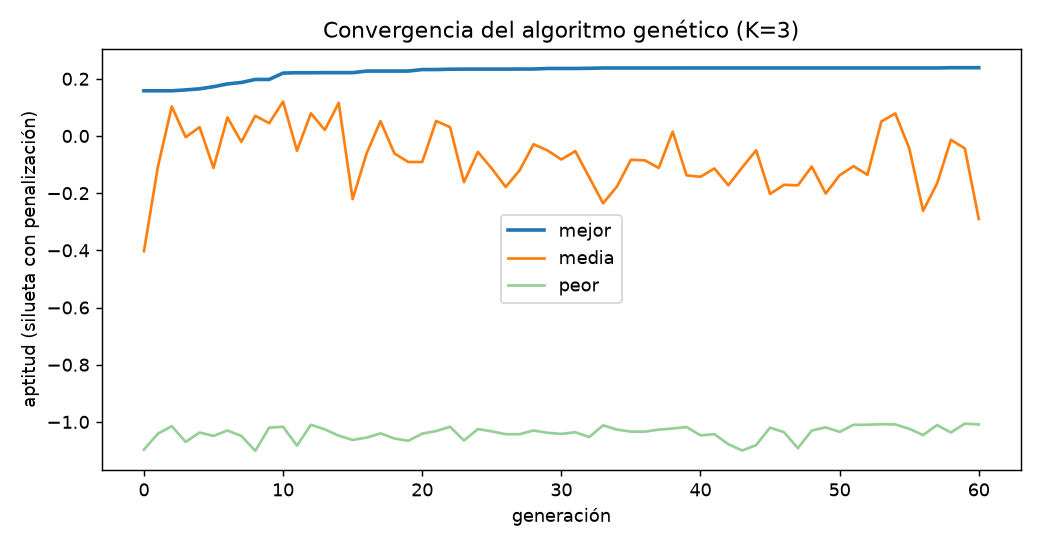

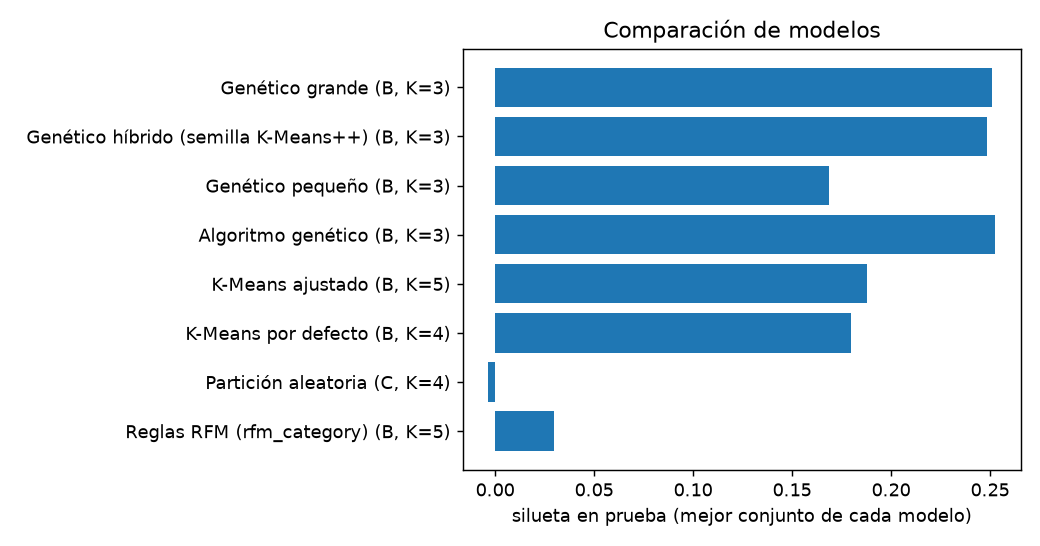

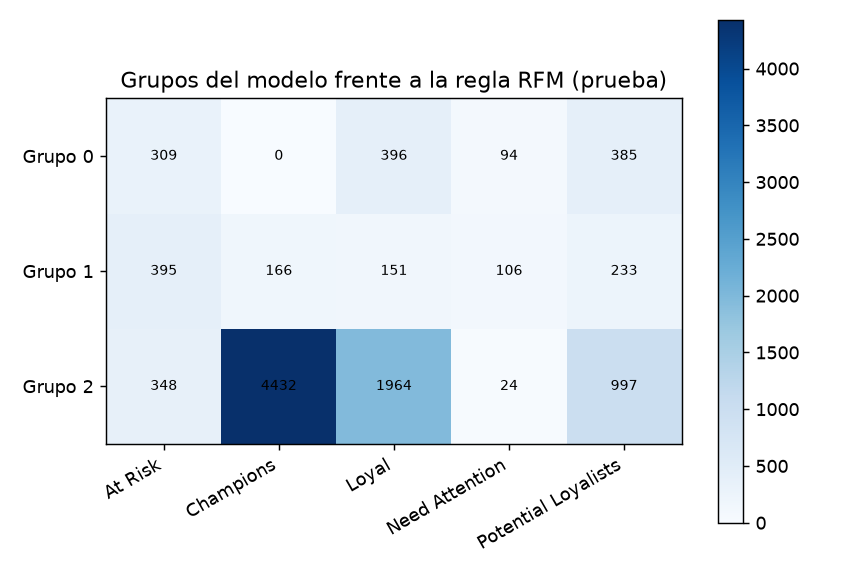

In [4]:
from IPython.display import Image, display
for archivo in ['convergencia', 'comparacion', 'grupos_vs_rfm']:
    display(Image(f'reports/{archivo}.png'))

## 4. Robustez con datasets generados

`src/data/generate.py` crea datasets con el mismo esquema; `estructura` es la fracción de clientes que sigue un arquetipo (0 = variables independientes, como en el original).

In [5]:
pd.read_csv('reports/robustez.csv').round(3)

,filas,estructura,modelo,k_elegido,silueta_test,ari_vs_arquetipo,ari_sin_ruido,ari_con_k5,tiempo_s
0,1000,0.0,K-Means,3,0.158,NaN,NaN,NaN,0.025
1,1000,0.0,Algoritmo genético,3,0.198,NaN,NaN,NaN,0.898
2,1000,0.6,K-Means,3,0.287,0.100,0.241,0.186,0.027
3,1000,0.6,Algoritmo genético,3,0.269,0.029,0.165,0.194,0.925
4,1000,1.0,K-Means,3,0.313,0.384,0.384,0.663,0.022
5,1000,1.0,Algoritmo genético,3,0.335,0.234,0.234,0.683,0.870
6,10000,0.0,K-Means,3,0.164,NaN,NaN,NaN,0.029
7,10000,0.0,Algoritmo genético,3,0.235,NaN,NaN,NaN,1.148
8,10000,0.6,K-Means,3,0.278,0.067,0.231,0.168,0.028
9,10000,0.6,Algoritmo genético,3,0.288,0.029,0.152,0.173,1.298


## 5. Inferencia: `predecir()`

Una llamada real con un cliente del dataset y un caso de error.

In [6]:
import json
from src.models.predict import predecir

cliente = pd.read_csv('data/raw/E-commerce_Customer_Segmentation_2026.csv').iloc[22].to_dict()
campos = ['days_since_last_purchase', 'total_purchases', 'tenure_months', 'avg_order_value_usd', 'return_count', 'complaint_count', 'satisfaction_score']
print('Entrada:', json.dumps({c: cliente[c] for c in campos}))
print('Salida:', json.dumps(predecir(cliente), ensure_ascii=False, indent=1))
print('Entrada incompleta:', json.dumps(predecir({'satisfaction_score': 3}), ensure_ascii=False))

Entrada: {"days_since_last_purchase": 12, "total_purchases": 194, "tenure_months": 118, "avg_order_value_usd": 872.32, "return_count": 12, "complaint_count": 2, "satisfaction_score": 5}
Salida: {
 "cluster_id": 2,
 "clase_etiqueta": "Grupo 2: compra reciente y muchas compras",
 "distancia_centroide": 2.8532,
 "confianza": 0.5793,
 "estatus_alerta": "Normal",
 "modelo": "Algoritmo genético (conjunto B, K=3)",
 "silueta_modelo_test": 0.2526,
 "tiempo_ms": 11.34,
 "status": "success"
}
Entrada incompleta: {"status": "error", "mensaje": "Faltan campos: ['days_since_last_purchase', 'total_purchases', 'tenure_months', 'avg_order_value_usd', 'return_count', 'complaint_count']", "campos_requeridos": ["days_since_last_purchase", "total_purchases", "tenure_months", "avg_order_value_usd", "return_count", "complaint_count", "satisfaction_score"]}


## 6. Pruebas

`pytest` verifica geometría, preprocesamiento sin fuga de datos, generador, algoritmo genético, contrato de `predecir()` y reproducibilidad.

In [7]:
r = subprocess.run([sys.executable, '-m', 'pytest', 'tests', '-q'], capture_output=True, text=True, encoding='utf-8')
print(r.stdout[-1500:])

..............................................                           [100%]
46 passed in 13.18s

